# Лабораторная работа № 8. Приватность и синтетические данные

**Вариант 6**

Сценарий — публикация учебного набора для сообщества. Целевая переменная — страховой случай в следующем периоде. Эталон, контроль и исходные таблицы полностью вымышлены. Генерация и разбиение используют seed 42. DP и часть атак используют независимую случайность.

## 1. Обнаружение и маскирование PII

| Тип | Поля |
|---|---|
| Прямые идентификаторы | ФИО, телефон, адрес, СНИЛС, ИНН, ОГРН и паспорт |
| Квазиидентификаторы | год рождения, город, продукт, год полиса |
| Чувствительные | страховой случай, история обращений, сумма выплаты |

Проверяем угрозу связывания по внешнему справочнику и утечки из свободного текста.

In [1]:
import os

import pandas as pd
from IPython.display import Image, display

from mock_insurance import validate_relations
from run import Experiment, WORK

lab = Experiment(reuse=os.environ.get('LAB8_REUSE') == '1')
print(validate_relations(lab.raw))
pii = lab.pii()
display(pd.DataFrame(pii['by_type']).T.round(3))
print('Точных совпадений в структурированных полях:', pii['structured_pii_overlap'])

{'clients': 15000, 'policies': 15000, 'agents': 8, 'claims': 3723, 'payments': 18172}


,tp,fp,fn,residual,precision,recall
name,46.0,2.0,2.0,0.0,0.958,0.958
phone,48.0,0.0,0.0,0.0,1.000,1.000
address,44.0,0.0,4.0,4.0,1.000,0.917
snils,44.0,1.0,4.0,4.0,0.978,0.917
inn,48.0,0.0,0.0,0.0,1.000,1.000
ogrn,48.0,0.0,0.0,0.0,1.000,1.000
passport,42.0,0.0,6.0,6.0,1.000,0.875


Точных совпадений в структурированных полях: 0


Presidio и Natasha нашли большую часть внедрённых идентификаторов. Остатки в адресах, СНИЛС и паспортах показывают, почему свободный текст исключён из выпуска. Структурированные поля маскируются целиком.

## 2. k-анонимность

Перебираем глобальные обобщения и выбираем минимальную потерю информации NCP для каждого порога. Независимую проверку k выполняет pycanon 1.3.6.

In [2]:
anonymity = lab.anonymity(pii)
rows = [dict(anonymity['baseline'], requested_k=1), *anonymity['choices']]
display(pd.DataFrame(rows)[['requested_k', 'k_min', 'singletons', 'groups_le_2', 'information_loss']].round(4))
print('Пример выделения одной вымышленной записи:', anonymity['linkage_example'])

,requested_k,k_min,singletons,groups_le_2,information_loss
0,1,1,4578,6893,0.0000
1,2,2,0,1,0.0837
2,5,5,0,0,0.1196
3,10,11,0,0,0.2500


Пример выделения одной вымышленной записи: {'birth_year': 2003, 'region': 'Омск', 'product': 'авто', 'policy_year': 2020, 'claim': 1}


Удаление прямых идентификаторов оставляет уникальные комбинации. При целевом k = 5 группы размера 1–2 исчезают с потерей NCP около 12 %. Это компромисс для этапа обобщения, выпуск проверяется отдельно.

## 3. Синтез и реляционная схема

Сравниваем GaussianCopula и CTGAN. CTGAN подбирается по ROC-AUC на внутренней валидации. Из сгенерированных профилей восстанавливаем дочерние таблицы по общим правилам и проверяем ключи.

In [3]:
sdv, samples = lab.synthesize()
display(pd.json_normalize(sdv['ctgan_tuning']).round(4))
display(pd.DataFrame([
    {'генератор': name, 'секунд': row['fit_s'], 'ROC-AUC': row['tstr']['auc'],
     'Shapes': row['fidelity']['column_shapes'], 'Pairs': row['fidelity']['column_pair_trends'],
     'FK errors': row['relations']['fk_errors'], 'PII': row['relations']['pii_overlap']}
    for name, row in sdv['models'].items()
]).round(4))

,validation_auc,fit_s,parameters.epochs,parameters.batch_size
0,0.5452,35.5584,12,500
1,0.5243,19.5450,24,1000
2,0.5369,76.2901,60,500


,генератор,секунд,ROC-AUC,Shapes,Pairs,FK errors,PII
0,gaussian_copula,6.5933,0.7607,0.8917,0.8809,0,0
1,ctgan,24.5643,0.4011,0.9376,0.7076,0,0


GaussianCopula сохраняет полезность лучше: при хорошем совпадении отдельных распределений CTGAN хуже воспроизводит зависимости, важные для прогноза.

## 4. Дифференциальная приватность

Сравниваем OpenDP, SmartNoise MWEM и MOSTLY AI TabularARGN при ε = 1, 3, 10. Для дискретного Лапласа δ = 0, для SDK и DP-SGD целевой δ = 10⁻⁵. Журнал содержит единицу приватности, модель соседства и метод учёта бюджета.

In [4]:
dp, candidate = lab.differentially_private()
display(pd.DataFrame([
    {'метод': row['method'], 'ε': row['requested_epsilon'], 'δ': row['delta'],
     'ROC-AUC TSTR': row['tstr']['auc'], 'доля baseline': row['relative_auc']}
    for row in dp['runs']
]).round(5))
display(pd.DataFrame({name: dp['dp_sgd'][name] for name in ('non_private', 'private')}).T.round(4))
print('Opacus:', dp['dp_sgd']['privacy'])
print('OpenDP при 300 профилях:', dp['low_volume']['tstr'])

,метод,ε,δ,ROC-AUC TSTR,доля baseline
0,opendp,1,0.00000,0.76170,0.99665
1,opendp,3,0.00000,0.76442,1.00020
2,opendp,10,0.00000,0.76353,0.99904
3,mwem,1,0.00000,0.66529,0.87049
4,mwem,3,0.00000,0.74940,0.98055
5,mwem,10,0.00000,0.71229,0.93200
6,mostlyai,1,0.00001,0.71866,0.94033
7,mostlyai,3,0.00001,0.74623,0.97640
8,mostlyai,10,0.00001,0.75217,0.98417


,auc,f1
non_private,0.7623,0.5015
private,0.7644,0.3973


Opacus: {'method': 'Opacus DP-SGD', 'operation': '12 эпох', 'requested_epsilon': None, 'epsilon_upper': 2.642622899322276, 'delta': 1e-05, 'unit': 'клиент: один профиль со всеми связанными данными', 'neighbor': 'добавление/удаление одного клиента', 'accountant': 'Opacus RDP'}
OpenDP при 300 профилях: {'auc': 0.6544834732754196, 'f1': 0.36531365313653136}


OpenDP использует пять заранее заданных гистограмм. Обучение с DP-SGD оцениваем отдельно. У MOSTLY AI бюджет SDK указан как номинальный, поскольку выбор чекпойнта по валидации отдельно не учтён. Приватность выпуска обосновываем механизмом OpenDP.

## 5. Метрики и приёмка

Базовая модель обучается на исходном мок-train. TSTR использует ту же задачу и тот же тест. Для Anonymeter контроль исключён из обучения. Порог для каждой атаки — верхняя граница 95 % ДИ контрольного успеха.

In [5]:
audit = lab.evaluate(dp, candidate, samples)
display(pd.DataFrame(audit['gates']).T)
display(pd.DataFrame(audit['attacks']).T[['main', 'control', 'control_ci95', 'risk']])
display(pd.DataFrame({key: audit['distances'][key] for key in ('synthetic', 'control')}).T.round(4))
print('Membership ROC-AUC:', round(audit['distances']['membership_auc'], 4))

,value,passed,limit
pii_overlap,0,True,NaN
rare_mapping,0,True,NaN
singling_out,0.156,True,0.210537
linkability,0.008,True,0.015133
inference,0.728,True,0.768301
utility,1.000203,True,0.9
coverage,"{'ages': True, 'districts': True, 'products': ...",True,NaN
fairness,0.124944,True,0.2
dp_report,"{'epsilon': 3.0, 'delta': 0, 'unit': 'клиент: ...",True,NaN


,main,control,control_ci95,risk
singling_out,0.156,0.16,"[0.11975380512206552, 0.2105368385348368]",0.0
linkability,0.008,0.0,"[8.673617379884035e-19, 0.015133299495444574]",0.007939
inference,0.728,0.716,"[0.6571618753149917, 0.768300539302976]",0.041141


,dcr_p05,dcr_median,nndr_median,exact_rows
synthetic,0.0193,0.0571,0.8043,0.0
control,0.0185,0.0551,0.8026,0.0


Membership ROC-AUC: 0.5004


Проверяем приемлемость только для текущего прогона. DCR и NNDR интерпретируем рядом с отложенным контролем, а возрастные группы сравниваем по размаху TPR.

## 6. Публикация и федеративная альтернатива

Три клиента Flower обучаются на разных группах округов. Агрегатор FedAvg получает параметры и число локальных записей.

Клиенты Flower: [3431, 2944, 4125]


,модель,auc,f1,round
0,"OpenDP, TSTR",0.7644,0.4836,NaN
1,"Flower, FedAvg",0.7650,0.4970,12.0


Вердикт: можно публиковать


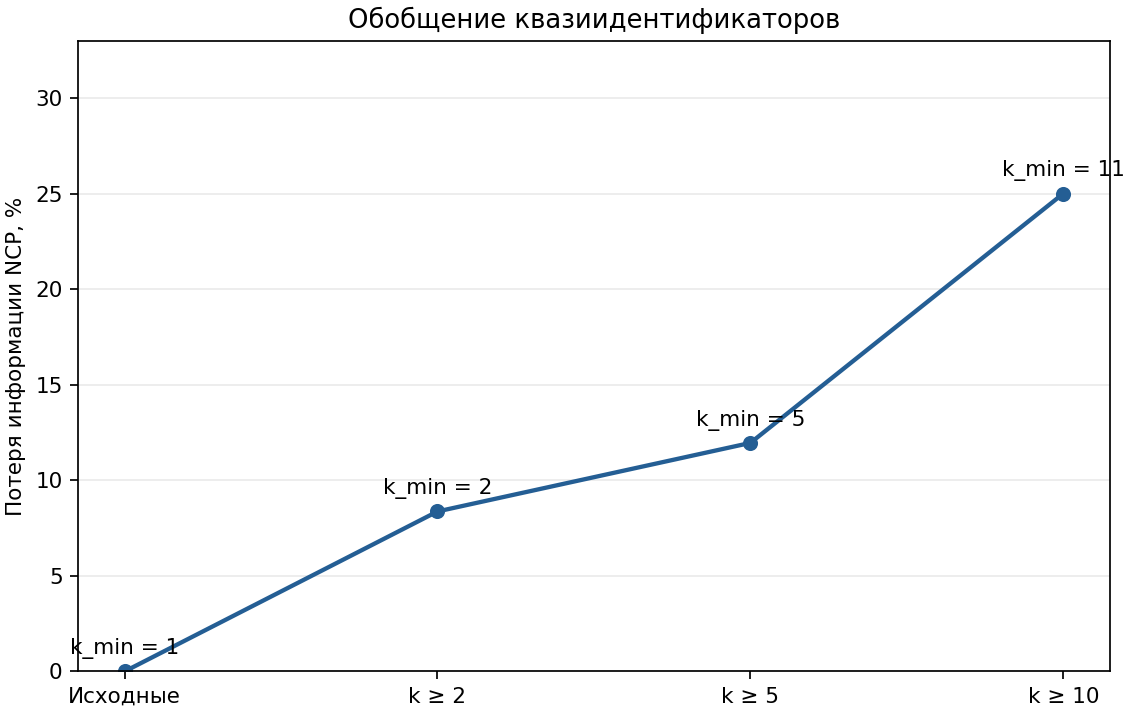

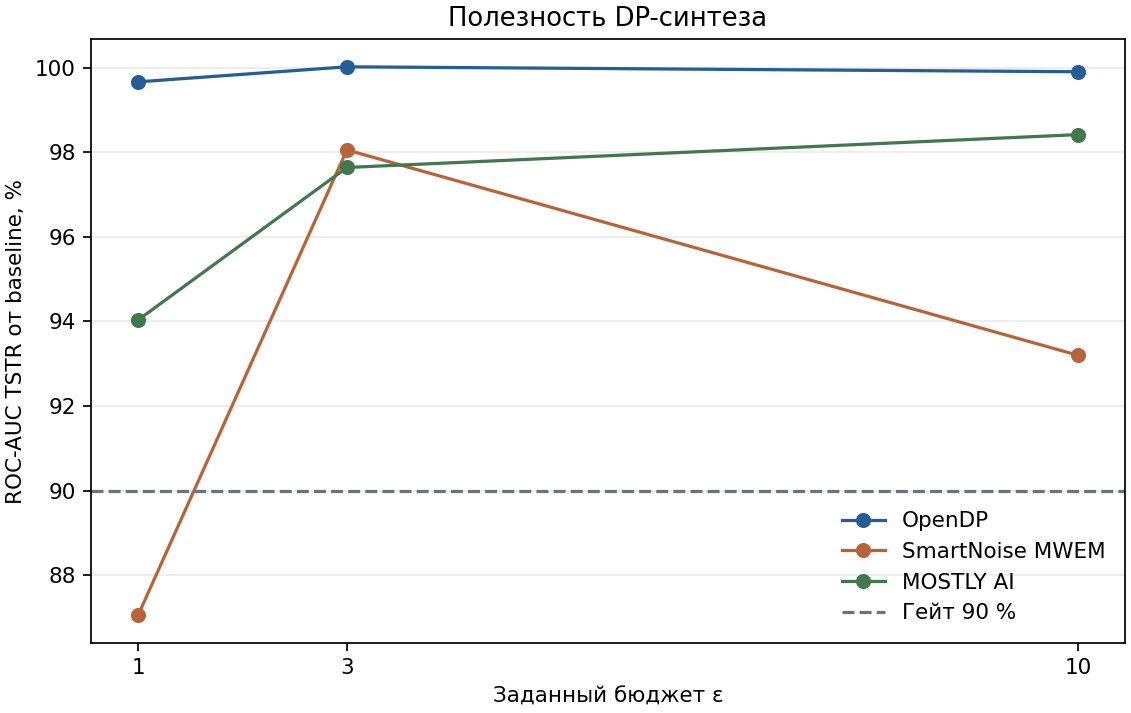

In [6]:
result = lab.finish(pii, anonymity, sdv, dp, audit, WORK / 'notebook')
print('Клиенты Flower:', result['federated']['clients'])
display(pd.DataFrame([{'модель': 'OpenDP, TSTR', **audit['tstr']},
                      {'модель': 'Flower, FedAvg', **result['federated']['final']}]).round(4))
print('Вердикт:', 'можно публиковать' if audit['passed'] else 'выпуск отклонён')
for chart in ('anonymity.png', 'dp_utility.png'):
    display(Image(filename=str(WORK / 'notebook' / chart), width=730))

Синтез подходит для сценария, где нужен набор для анализа. Федеративное обучение подходит, когда нужен прогноз и записи остаются у участников. В симуляции проверена агрегация обновлений внутри процесса. Итоговые значения и карточка выпуска вынесены в [отчёт](report.md).